# Data Cleaning & Preprocessing

This notebook covers all preprocessing steps applied to the raw athlete monitoring 
dataset before it is passed to the machine learning models. The steps are:

1. Dataset Overview
2. Imports
3. Handling Missing & Incorrect Values
4. Feature Engineering — Imminent Risk Window
5. Train/Test Split
6. Removal of Identifiers
7. Correlation Analysis & Feature Selection
8. Normalization
9. Export
10. Summary

### 1. Dataset

In [1]:
DATA_PATH = "../data/daily_injury_data.csv"

### 2. Imports

In [14]:
# keep your existing imports exactly as they are
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score
from IPython.display import display

### 3. Handling of missing values (NaN) and incorrect values

In this step, we performed an analysis of missing values to ensure the integrity of our data before modeling.

#### 3.1. Identification of Missing Values

We first verified that were no standard `NaN`values in the dataset. However, we identified that a negative value (-0.01) indicated a lack of data, similar to `NaN`in other datasets.

In [15]:
df = pd.read_csv(DATA_PATH)

# check NaNs 
total_nans = df.isna().sum().sum()
print(f"Total NaN values in the dataset: {total_nans}\n")
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")

Total NaN values in the dataset: 0

Dataset shape: 42766 rows × 73 columns


### 3.2. Percentage Analysis of Missing Values

The -0.01 sentinel values appear exclusively in the **subjective columns** 
(`perceived exertion`, `perceived trainingSuccess`, `perceived recovery`) 
and consistently affect approximately **26.8% of rows** across all 7 days 
of the sliding window. Since this is a consistent pattern rather than random 
missingness, and because these days carry meaningful information (rest days), 
we chose **not to drop these rows**.

In [16]:
# Check for negative sentinel values (-0.01)
total_rows = len(df)
negative_counts = (df < 0).sum()
cols_with_negatives = negative_counts[negative_counts > 0]

percent_negatives = (cols_with_negatives / total_rows) * 100

negative_analysis = pd.DataFrame({
    'Percentage (%)': percent_negatives.round(2)
})
display(negative_analysis)
print("Table 1: Percentage of Missing Values (-0.01) per Column")

,Percentage (%)
perceived exertion,26.83
perceived trainingSuccess,26.83
perceived recovery,26.83
perceived exertion.1,26.90
perceived trainingSuccess.1,26.90
perceived recovery.1,26.90
perceived exertion.2,26.84
perceived trainingSuccess.2,26.84
perceived recovery.2,26.84
perceived exertion.3,26.84


Table 1: Percentage of Missing Values (-0.01) per Column


### 3.3. Why Negative Values Appear — Rest Day Hypothesis

Our hypothesis was that athletes did not fill in the subjective questionnaire 
on days they did not train. To confirm this, we cross-referenced every -0.01 
entry with the physical training columns (e.g. `total km`). 

The analysis confirmed that on **100% of the days with missing questionnaire 
data, the total physical load was exactly 0.0** — validating that these are 
genuine rest days, not data collection errors.

In [19]:
days_without_quest = df[df['perceived exertion'] == -0.01]
days_with_quest = df[df['perceived exertion'] != -0.01]
physical_cols = ['total km', 'km Z3-4', 'km sprinting', 'hours alternative']

comparison_df = pd.DataFrame({
    'No Questionnaire (-0.01)': days_without_quest[physical_cols].sum(),
    'With Questionnaire (Valid)': days_with_quest[physical_cols].sum()
})

styled_comparison = comparison_df.style.set_properties(
    **{'text-align': 'center'}).format("{:.1f}")
display(styled_comparison)
print("Table 2: Total Accumulated Physical Load — Rest Days vs Training Days")

,No Questionnaire (-0.01),With Questionnaire (Valid)
total km,0.0,300995.1
km Z3-4,0.0,29567.6
km sprinting,0.0,3122.6
hours alternative,0.0,6991.9


Table 2: Total Accumulated Physical Load — Rest Days vs Training Days


### 3.4. Interpretation of Zero Values

Columns like `total km` and `nr. sessions` contain many zero values. 
These are **not errors** — they represent **rest days**, which account 
for approximately **40.5%** of the dataset.

From a sports science perspective, rest days are essential context for the model. 
Removing them would mean the model only ever sees training load and could never 
learn to distinguish a healthy training-rest cycle from dangerous overtraining 
or inadequate recovery. All zero values are therefore preserved as-is.

## 4. Feature Engineering — Imminent Risk Window

Raw injury labels only mark the **day of injury** (Day 0). However, from a 
sports medicine perspective, an injury does happen due to physiological stress accumulated.

To capture this, we created a new target variable `Risk_Zone` that marks 
not only the day of injury but also the **3 days immediately before it**. 
This transforms the problem from "predict today's injury" to 
"predict imminent injury risk".

**Result of this transformation:**
- Original injury days: **583**
- Imminent Risk days (new target): **1,710** (~4.0% of all observations)

In [21]:
# sort chronologically per athlete 
df = df.sort_values(by=['Athlete ID', 'Date']).reset_index(drop=True)

# initialize Risk_Zone with the original injury column (Day 0)
df['Risk_Zone'] = df['injury']

# if an injury occurs in the next 3 days, mark the current day as Imminent Risk 
for i in range(1, 4):
    future_injury = df.groupby('Athlete ID')['injury'].shift(-i).fillna(0)
    df['Risk_Zone'] = (df['Risk_Zone'] | future_injury.astype(int))

print("--- Target Variable Transformation ---")
print(f"Original Injury Days:            {df['injury'].sum()}")
print(f"Imminent Risk Days (Risk_Zone):  {df['Risk_Zone'].sum()}")
print(f"Risk Zone as % of dataset:       {df['Risk_Zone'].mean()*100:.1f}%")

--- Target Variable Transformation ---
Original Injury Days:            583
Imminent Risk Days (Risk_Zone):  1710
Risk Zone as % of dataset:       4.0%


## 5. Train/Test Split

After engineering the target variable, the data is split into Training (80%) 
and Testing (20%) sets. A standard random split was **not used** for two reasons:

- **Data Leakage:** The 7-day sliding window means consecutive rows share 6 days 
  of data. A random split would place overlapping windows in both sets, allowing 
  the model to indirectly "see" test data during training.
- **Class Imbalance Risk:** With only ~4% injury days, a random split could 
  result in a test set with very few or zero injury cases, making evaluation 
  unreliable.

Instead, we implemented a **Stratified Group Split by Athlete**:
- Athletes were divided into two groups: those with at least one risk event (63 athletes) 
  and those completely healthy (11 athletes)
- 80% of each group was randomly assigned to training, 20% to testing
- This ensures both sets have injury cases while keeping each athlete's data 
  entirely in one set, preventing any temporal leakage

In [22]:
# separate athletes by groups
athlete_injury_history = df.groupby('Athlete ID')['Risk_Zone'].sum() > 
injured_athletes = athlete_injury_history[athlete_injury_history == True].index.to_numpy()
healthy_athletes = athlete_injury_history[athlete_injury_history == False].index.to_numpy()

print(f"Athletes with risk events: {len(injured_athletes)}")
print(f"Athletes completely healthy: {len(healthy_athletes)}")

# 80/20 split within each group
np.random.seed(42)

train_injured = np.random.choice(injured_athletes, size=int(0.8 * len(injured_athletes)), replace=False)
train_healthy = np.random.choice(healthy_athletes, size=int(0.8 * len(healthy_athletes)), replace=False)

train_ids = np.concatenate([train_injured, train_healthy])

# split the DataFrame
train_df = df[df['Athlete ID'].isin(train_ids)].copy()
test_df  = df[~df['Athlete ID'].isin(train_ids)].copy()

total_rows = len(df)
total_injuries = df['Risk_Zone'].sum()

print("\n--- Train / Test Split Summary ---")
print(f"Training Set: {len(train_df):,} rows ({len(train_df)/total_rows*100:.1f}%) "
      f"| Risk Days: {train_df['Risk_Zone'].sum()} "
      f"({train_df['Risk_Zone'].sum()/total_injuries*100:.1f}% of all risk days)")
print(f"Testing Set:  {len(test_df):,} rows ({len(test_df)/total_rows*100:.1f}%) "
      f"| Risk Days: {test_df['Risk_Zone'].sum()} "
      f"({test_df['Risk_Zone'].sum()/total_injuries*100:.1f}% of all risk days)")

Athletes with risk events: 63
Athletes completely healthy: 11

--- Train / Test Split Summary ---
Training Set: 33,434 rows (78.2%) | Risk Days: 1267 (74.1% of all risk days)
Testing Set:  9,332 rows (21.8%) | Risk Days: 443 (25.9% of all risk days)


## 6. Removal of Identifiers (IDs and Dates)

Before passing the data to any model, we remove `Athlete ID` and `Date`. 

- **Athlete ID:** Removing this prevents the model from learning that a specific 
  athlete gets injured frequently — we want it to learn physiological patterns, 
  not athlete identities.
- **Date:** Removing this prevents the model from finding spurious temporal 
  correlations (e.g. "injuries happen more in winter") that may not generalize.

The test set identifiers are saved separately so predictions can later be 
mapped back to real athletes and dates for error analysis.

In [24]:
# Save identifiers for later error analysis
test_identifiers = test_df[['Athlete ID', 'Date']].copy()

cols_to_drop = ['Athlete ID', 'Date']

# X: all features except identifiers and both target columns
X_train = train_df.drop(columns=cols_to_drop + ['injury', 'Risk_Zone'])
X_test  = test_df.drop(columns=cols_to_drop + ['injury', 'Risk_Zone'])

# y: the engineered risk window target
y_train = train_df['Risk_Zone']
y_test  = test_df['Risk_Zone']

print(f"Features in dataset: {X_train.shape[1]}")
print(f"Training set: {X_train.shape[0]:,} rows × {X_train.shape[1]} features")
print(f"Testing set:  {X_test.shape[0]:,} rows × {X_test.shape[1]} features")
print(f"\nTraining risk days: {y_train.sum()} ({y_train.mean()*100:.1f}%)")
print(f"Testing risk days:  {y_test.sum()} ({y_test.mean()*100:.1f}%)")

Features in dataset: 70
Training set: 33,434 rows × 70 features
Testing set:  9,332 rows × 70 features

Training risk days: 1267 (3.8%)
Testing risk days:  443 (4.7%)


**Note:** We have stored the IDs and Dates of the test set in `test_identifiers`. This ensures that the model remains completely unaware of these identifiers during evaluation to prevent bias.
However, we can later map the model's predictions back to real athletes and dates from prehensive error analysis and results interpretation.

## 7. Correlation Analysis & Feature Selection

We analyzed the relationships between base features (current day only) 
to detect redundancy. Since all 70 features are time-shifted versions of 
the same 10 base variables, any redundancy found at the base level applies 
across the entire window — so we only need to check the 10 base columns.

We used a threshold of **0.85** — pairs above this would indicate one feature 
is largely redundant and a candidate for removal.

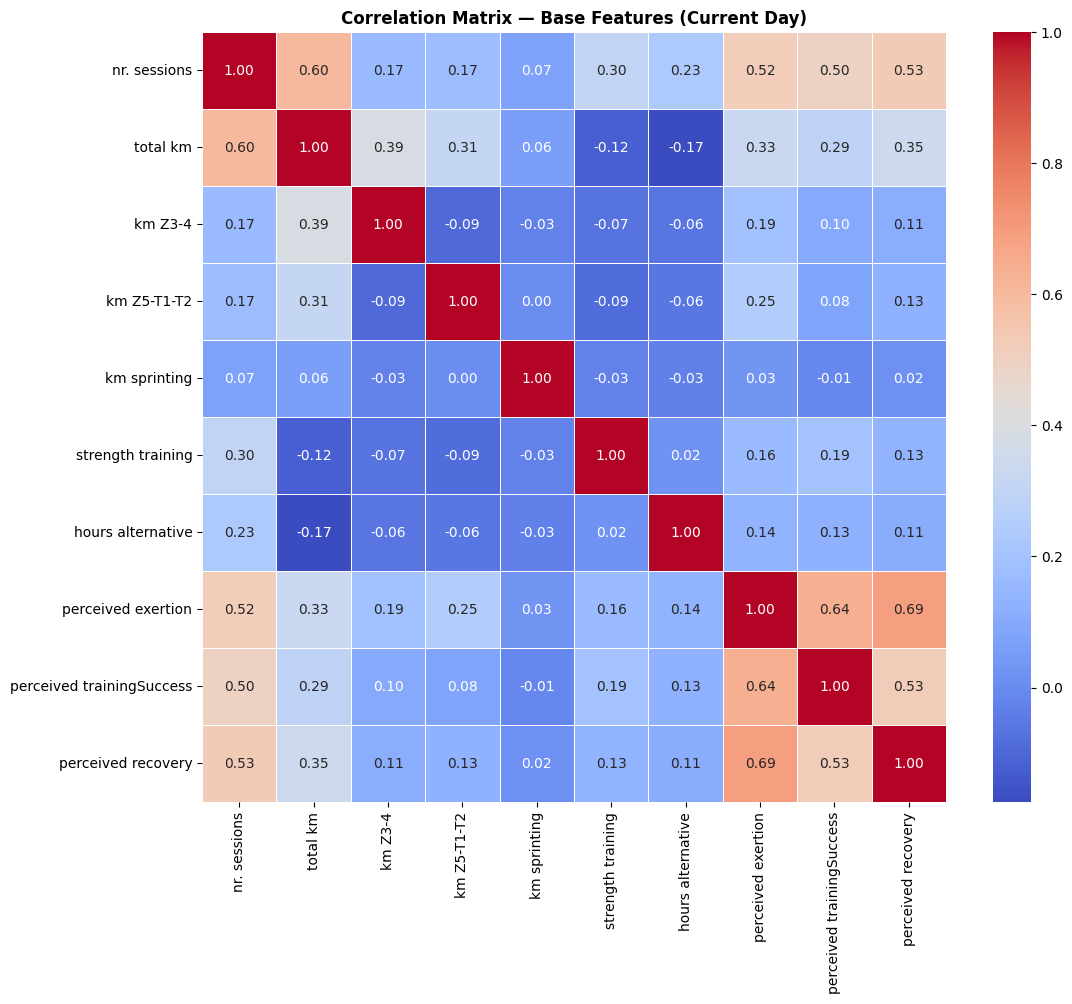

In [25]:
lag_suffixes = ('.1', '.2', '.3', '.4', '.5', '.6')
base_cols = [col for col in X_train.columns if not col.endswith(lag_suffixes)]

corr_matrix = X_train[base_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix — Base Features (Current Day)", fontweight='bold')
plt.show()

### 7.1. Matrix Analysis

No feature pair exceeded the **0.85 correlation threshold**, so no features 
were removed. The notable correlations found were:

- `perceived exertion` ↔ `perceived recovery`: **0.69** — the highest pair. 
  Despite this, both were kept because they measure conceptually different things: 
  exertion measures effort output, while recovery measures how well the athlete 
  feels they are recuperating. A tired athlete (high exertion) may or may not 
  recover well, and this distinction is clinically relevant.
- `perceived exertion` ↔ `perceived trainingSuccess`: **0.64**
- `nr. sessions` ↔ `total km`: **0.60** — expected, as more sessions naturally 
  produce more total distance.

### 7.2. Modeling Strategy

Given that subjective features show the highest inter-correlations, we implemented 
two parallel feature sets for the modeling phase:

- **Full Model (70 features):** All objective + subjective features
- **Objective-Only Model (49 features):** Physical load metrics only, 
  excluding all `perceived` columns

This allows us to later evaluate whether subjective athlete feedback 
meaningfully improves injury prediction over physical data alone.

In [26]:
# Features for the Objectives-Only Model
X_train_objective = X_train.loc[:, ~X_train.columns.str.contains('perceived')]
X_test_objective  = X_test.loc[:,  ~X_test.columns.str.contains('perceived')]

print(f"Full model features:           {X_train.shape[1]}")
print(f"Objective-only model features: {X_train_objective.shape[1]}")
print(f"Subjective features removed:   {X_train.shape[1] - X_train_objective.shape[1]}")

Full model features:           70
Objective-only model features: 49
Subjective features removed:   21


### 7. Normalization (Min-Max Scaling)

In this final step, we transform all features to a common scale between 0 and 1, because due to the different ranges between columns, the model might worngly assume that larger numbers are important.

We chose **Min-Max Normalization** over Standardization because it preserves the relationship between training and rest days.
In our dataset, a value of 0 represents a rest day and if we chose Standardization, it would be transformed into a negative value, which would make it harder for the model to distinguish betweem low-effort days and actual recovery days.

In [11]:
scaler = MinMaxScaler()

# full model features normalization
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

display(X_train.head())
print("Table 3: Normalization Full Model\n")

,nr. sessions,total km,km Z3-4,km Z5-T1-T2,km sprinting,strength training,hours alternative,perceived exertion,perceived trainingSuccess,perceived recovery,...,nr. sessions.6,total km.6,km Z3-4.6,km Z5-T1-T2.6,km sprinting.6,strength training.6,hours alternative.6,perceived exertion.6,perceived trainingSuccess.6,perceived recovery.6
0,0.5,0.105455,0.0,0.0125,0.03,0.0,0.000000,0.118812,0.009901,0.188119,...,0.5,0.000000,0.000000,0.000000,0.00,0.0,0.05,0.108911,0.009901,0.158416
1,0.0,0.000000,0.0,0.0000,0.00,0.0,0.000000,0.000000,0.000000,0.000000,...,0.5,0.094545,0.000000,0.010417,0.03,0.0,0.00,0.108911,0.009901,0.178218
2,0.5,0.000000,0.0,0.0000,0.00,0.5,0.000000,0.108911,0.009901,0.178218,...,0.0,0.000000,0.000000,0.000000,0.00,0.0,0.00,0.000000,0.000000,0.000000
3,0.0,0.000000,0.0,0.0000,0.00,0.0,0.000000,0.000000,0.000000,0.000000,...,0.5,0.000000,0.000000,0.000000,0.00,0.5,0.00,0.108911,0.009901,0.178218
4,0.5,0.000000,0.0,0.0000,0.00,0.0,0.105675,0.089109,0.009901,0.188119,...,0.5,0.320000,0.170616,0.000000,0.00,0.0,0.00,0.118812,0.009901,0.178218


Table 3: Normalization Full Model



In [12]:
# objectives-only model features normalization
scaler_obj = MinMaxScaler()
X_train_obj_scaled = scaler_obj.fit_transform(X_train_objective)
X_test_obj_scaled = scaler_obj.transform(X_test_objective)

X_train_objective = pd.DataFrame(X_train_obj_scaled, columns=X_train_objective.columns, index=X_train_objective.index)
X_test_objective = pd.DataFrame(X_test_obj_scaled, columns=X_test_objective.columns, index=X_test_objective.index)

display(X_train_objective.head())
print("Table 4: Normalization Objectives-Only Model\n")

,nr. sessions,total km,km Z3-4,km Z5-T1-T2,km sprinting,strength training,hours alternative,nr. sessions.1,total km.1,km Z3-4.1,...,km sprinting.5,strength training.5,hours alternative.5,nr. sessions.6,total km.6,km Z3-4.6,km Z5-T1-T2.6,km sprinting.6,strength training.6,hours alternative.6
0,0.5,0.105455,0.0,0.0125,0.03,0.0,0.000000,0.0,0.000000,0.000000,...,0.00,0.5,0.000000,0.5,0.000000,0.000000,0.000000,0.00,0.0,0.05
1,0.0,0.000000,0.0,0.0000,0.00,0.0,0.000000,0.5,0.000000,0.000000,...,0.00,0.0,0.103413,0.5,0.094545,0.000000,0.010417,0.03,0.0,0.00
2,0.5,0.000000,0.0,0.0000,0.00,0.5,0.000000,0.0,0.000000,0.000000,...,0.03,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.00,0.0,0.00
3,0.0,0.000000,0.0,0.0000,0.00,0.0,0.000000,0.5,0.000000,0.000000,...,0.00,0.0,0.000000,0.5,0.000000,0.000000,0.000000,0.00,0.5,0.00
4,0.5,0.000000,0.0,0.0000,0.00,0.0,0.105675,0.5,0.298182,0.236967,...,0.00,0.5,0.000000,0.5,0.320000,0.170616,0.000000,0.00,0.0,0.00


Table 4: Normalization Objectives-Only Model



### 8. Export new datasets

In [27]:
X_train.to_csv("../data/X_train_risk.csv", index=True)
X_test.to_csv("../data/X_test_risk.csv",  index=True)
y_train.to_csv("../data/y_train_risk.csv", index=True)
y_test.to_csv("../data/y_test_risk.csv",  index=True)

X_train_objective.to_csv("../data/X_train_obj_risk.csv", index=True)
X_test_objective.to_csv("../data/X_test_obj_risk.csv",  index=True)

print("✓ Files exported to ../data/:")

✓ Files exported to ../data/:


### 9. Summary

1.  **Full Dataset:** 70 features (including 21 subjective metrics).
2.  **Objective Dataset:** 49 features (strictly physical load metrics).

**Final Dataset Integrity:**
- **Zero Values:** Maintained as 0.0 to represent recovery/rest periods.
- **Scaling:** All features are now normalized within the [0, 1] range.
- **Leakage Prevention:** Training and testing sets remain completely isolated by athlete and scale distribution.
- **Target:** The `injury` column is isolated in `y_train` and `y_test`, ready for supervised learning.